In [ ]:
# region import
import numpy as np
import pandas as pd
from backtesting import Strategy, Backtest
import joblib
import talib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from backtesting import Backtest
# endregion

/Users/leoinv/Documents/CODE/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/leoinv/Documents/CODE/.venv/lib/python3.12/site-packages/backtesting/_plotting.py:55: UserWarning: Jupyter Notebook detected. Setting Bokeh output to notebook. This may not work in Jupyter clients without JavaScript support, such as old IDEs. Reset with `backtesting.set_bokeh_output(notebook=False)`.
  warnings.warn('Jupyter Notebook detected. '


Loading BokehJS ...

In [ ]:
class RSI_MACD(Strategy):
    lookback = 14
    threshold = 0.165
    sl_mult = 4.5

    def init(self):
        self.atr = self.I(talib.ATR, self.data.High, self.data.Low, self.data.Close,
                          timeperiod=self.lookback, plot=False)
        atr_series = pd.Series(self.atr, index=self.data.index)

        _, _, self.hist = self.I(talib.MACD, self.data.Close / atr_series.shift())
        self.rsi_macd = self.I(talib.RSI, self.hist, self.lookback, plot=False)

        self.rsi = self.I(talib.RSI, self.data.Close, self.lookback, plot=False)
        _, _, self.hist_rsi = self.I(talib.MACD, self.rsi)

        self.trend_ma = self.I(talib.EMA, self.data.Close, 200)
        self.exit_ma = self.I(talib.EMA, self.data.Close, 100)

    def next(self):
        price = self.data.Close[-1]
        rsi_macd = self.rsi_macd[-1]
        hist_rsi = self.hist_rsi[-1]
        rsi = self.rsi[-1]
        hist = self.hist[-1]
        trend_ma = self.trend_ma[-1]
        exit_ma = self.exit_ma[-1]
        atr = self.atr[-1]

        size = 0.1

        long_cond = (
            rsi_macd <= 30 and rsi >= 40
            and hist <= -self.threshold * 2 and hist_rsi <= -self.threshold
            and price >= trend_ma
        )
        short_cond = (
            rsi_macd >= 70 and rsi <= 60
            and hist >= self.threshold * 2 and hist_rsi >= self.threshold
            and price <= exit_ma 
        )

        if long_cond and not self.position.is_long:
            sl = price - self.sl_mult * atr
            self.buy(size=size, sl = sl)

        if short_cond and self.position.is_long:
            self.position.close()

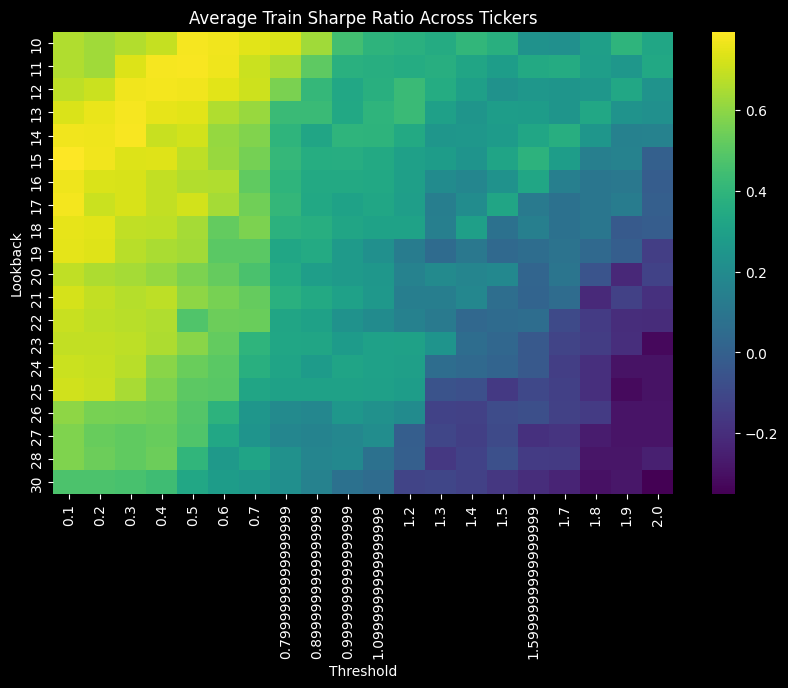


Averaged params → Lookback: 13, Threshold: 0.320


In [ ]:
datas = joblib.load('/Users/leoinv/Documents/CODE/BACKTEST/data/1h.joblib')

train_ratio = 0.7
lookbacks = np.linspace(10, 30, 20, dtype=int)
thresholds = np.linspace(0.1, 2, 20)

# Step 1: Sweep Sharpe across all tickers' train sets
sweep_results = []
i = 0
for ticker, data in datas.items():
    i += 1
    if i > 10:
        break
    if ticker == 'XLMUSDT':
        continue
    data.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']
    data.set_index('Date', inplace=True)
    data = data.dropna()

    if len(data) <= 30000:
        continue

    # Split train/test
    split_idx = int(len(data) * train_ratio)
    train_data = data.iloc[:split_idx]

    for lb in lookbacks:
        for th in thresholds:
            bt_train = Backtest(train_data, RSI_MACD,
                                cash=1000000000, commission=.0005)
            stats = bt_train.run(lookback=lb, threshold=th)
            sweep_results.append((lb, th, stats['Sharpe Ratio'], ticker))

# Step 2: Average Sharpe for each param pair
df_sweep = pd.DataFrame(sweep_results, columns=['Lookback', 'Threshold', 'Sharpe', 'Ticker'])
avg_sweep = df_sweep.groupby(['Lookback', 'Threshold'])['Sharpe'].mean().reset_index()

# Step 3: Create heatmap
pivot = avg_sweep.pivot(index='Lookback', columns='Threshold', values='Sharpe')

plt.style.use('dark_background')
plt.figure(figsize=(10, 6))
sns.heatmap(pivot, cmap='viridis', annot=False)
plt.title("Average Train Sharpe Ratio Across Tickers")
plt.show()

# Get top 3 rows by Sharpe
top5 = avg_sweep.nlargest(5, 'Sharpe')

# Average their parameters
best_lookback = int(round(top5['Lookback'].mean()))
best_threshold = top5['Threshold'].mean()

print(f"\nAveraged params → Lookback: {best_lookback}, Threshold: {best_threshold:.3f}")

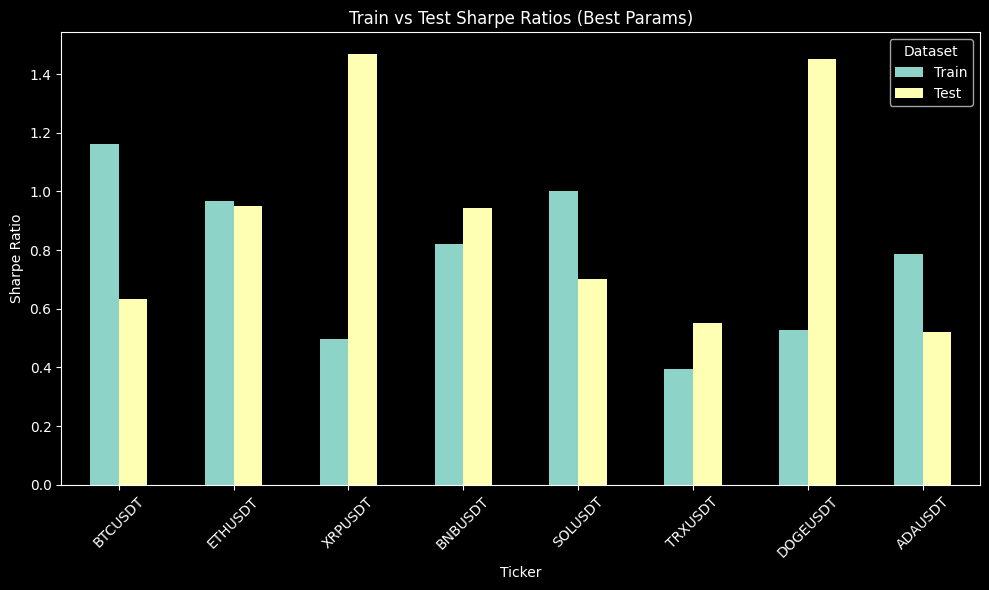

In [ ]:
# Step 5: Run test set with best params
train_results = {}
test_results = {}

train_equities = {}
test_equities = {}

i = 0
for ticker, data in datas.items():
    if ticker == 'XLMUSDT':
        continue
    i += 1
    if i > 10:
        break
    data = data.dropna()

    if len(data) <= 30000:
        continue

    split_idx = int(len(data) * train_ratio)
    train_data = data.iloc[:split_idx]
    test_data = data.iloc[split_idx:]

    # Train run
    bt_train = Backtest(train_data, RSI_MACD, cash=1000000000, commission=.0005)
    stats_train = bt_train.run(lookback=best_lookback, threshold=best_threshold)
    train_results[ticker] = stats_train['Sharpe Ratio']
    train_equities[ticker] = stats_train['_equity_curve']['Equity'].pct_change().cumsum() + 1

    # Test run
    bt_test = Backtest(test_data, RSI_MACD, cash=1000000000, commission=.0005)
    stats_test = bt_test.run(lookback=best_lookback, threshold=best_threshold)
    test_results[ticker] = stats_test['Sharpe Ratio']
    test_equities[ticker] = stats_test['_equity_curve']['Equity'].pct_change().cumsum() + 1

# Step 6: Compare Train vs Test Sharpe
df_results = pd.DataFrame({
    "Train": pd.Series(train_results),
    "Test": pd.Series(test_results)
}).dropna(how="all")

df_results.plot(kind='bar', figsize=(10, 6))
plt.title("Train vs Test Sharpe Ratios (Best Params)")
plt.ylabel("Sharpe Ratio")
plt.xlabel("Ticker")
plt.xticks(rotation=45)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

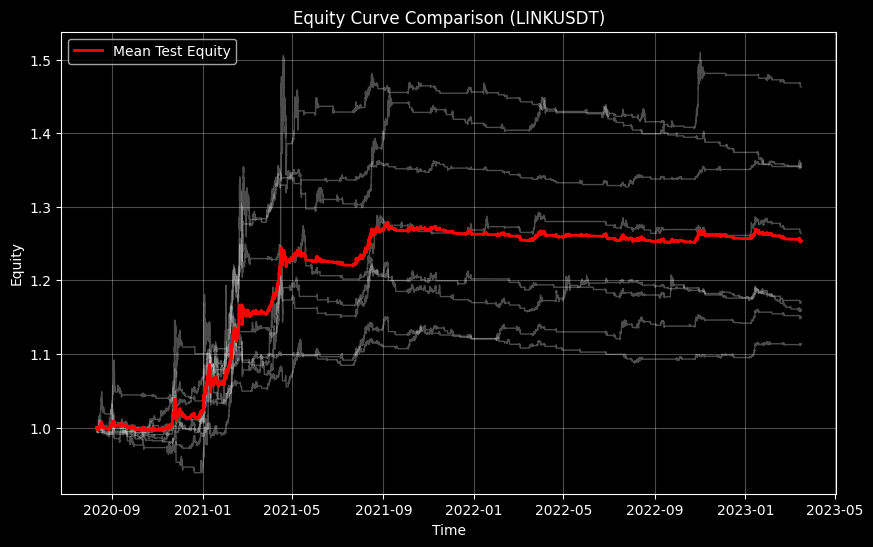

               CAR  Volatility  Sharpe Ratio  Max Drawdown  Calmar Ratio
BTCUSDT   0.042522    0.031716      1.314589     -0.043756      0.971808
ETHUSDT   0.055264    0.047040      1.143571     -0.049640      1.113309
XRPUSDT   0.062727    0.081092      0.752325     -0.102626      0.611214
BNBUSDT   0.125486    0.074652      1.586898     -0.085308      1.470980
SOLUSDT   0.124055    0.107494      1.087943     -0.090299      1.373825
TRXUSDT   0.058400    0.075262      0.754927     -0.056392      1.035611
DOGEUSDT  0.157908    0.118215      1.240294     -0.107886      1.463655
ADAUSDT   0.094761    0.073315      1.234296     -0.058038      1.632736

Mean: CAR             0.090140
Volatility      0.076098
Sharpe Ratio    1.139355
Max Drawdown   -0.074243
Calmar Ratio    1.209142
dtype: float64


In [ ]:
df_train = pd.DataFrame(train_equities).dropna().pct_change().cumsum() + 1
df_test = pd.DataFrame(test_equities)

# Calculate mean test equity curve
mean_train_equity = df_train.mean(axis=1)

# Plot
plt.figure(figsize=(10, 6))

# Plot test equities (all in white)
for col in df_train.columns:
    plt.plot(df_train[col], color='white', alpha=0.3, linewidth=1, label='_nolegend_')

# Plot mean of test equities in red
plt.plot(mean_train_equity, color='red', linewidth=2, label='Mean Test Equity')

# Titles and style
plt.title(f"Equity Curve Comparison ({ticker})")
plt.xlabel("Time")
plt.ylabel("Equity")
plt.grid(True, alpha=0.3)
plt.legend()

# Black background for contrast
plt.gca().set_facecolor('black')
plt.show()

from utils import performance_metrics
results = {}
for ticker in df_train.columns:
   results[ticker] = performance_metrics(df_train[ticker], periods_per_year=24* 365)

result_df = pd.DataFrame(results).T
print(result_df)
print(f"\nMean: {result_df.mean()}")

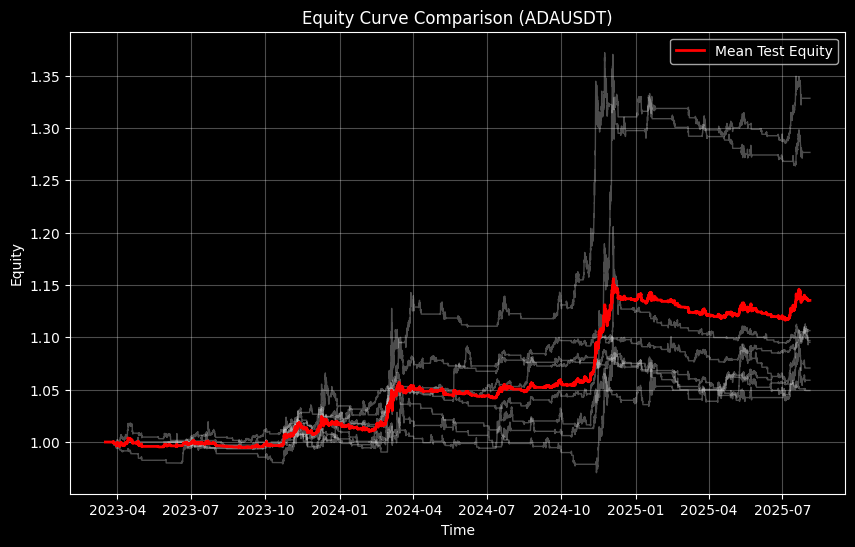

               CAR  Volatility  Sharpe Ratio  Max Drawdown  Calmar Ratio
BTCUSDT   0.020334    0.029916      0.672931     -0.035728      0.569138
ETHUSDT   0.038850    0.036374      1.047894     -0.040348      0.962866
XRPUSDT   0.139535    0.080625      1.620188     -0.061904      2.254068
BNBUSDT   0.040682    0.039390      1.012395     -0.031773      1.280393
SOLUSDT   0.039118    0.057648      0.665682     -0.048792      0.801734
TRXUSDT   0.048344    0.043767      1.078757     -0.092393      0.523239
DOGEUSDT  0.143242    0.088679      1.509680     -0.078863      1.816345
ADAUSDT   0.031708    0.062995      0.495559     -0.089409      0.354645

Mean: CAR             0.062727
Volatility      0.054924
Sharpe Ratio    1.012886
Max Drawdown   -0.059901
Calmar Ratio    1.070303
dtype: float64


In [ ]:
# Calculate mean test equity curve
mean_test_equity = df_test.mean(axis=1)

# Plot
plt.figure(figsize=(10, 6))

# Plot test equities (all in white)
for col in df_test.columns:
    plt.plot(df_test[col], color='white', alpha=0.3, linewidth=1, label='_nolegend_')

# Plot mean of test equities in red
plt.plot(mean_test_equity, color='red', linewidth=2, label='Mean Test Equity')

# Titles and style
plt.title(f"Equity Curve Comparison ({ticker})")
plt.xlabel("Time")
plt.ylabel("Equity")
plt.grid(True, alpha=0.3)
plt.legend()

# Black background for contrast
plt.gca().set_facecolor('black')
plt.show()

from utils import performance_metrics
results = {}
for ticker in df_test.columns:
   results[ticker] = performance_metrics(df_test[ticker], periods_per_year=24* 365)


result_df = pd.DataFrame(results).T
print(result_df)
print(f"\nMean: {result_df.mean()}")